# Caso 29. Distribución muestral de la media

**Nombre:** Kevin Abraham Fernandez Sanchez
**Matrícula:** 25041246
**Materia:** Probabilidad y Estadística
**Carrera:** Ingeniería Informática, Instituto Tecnológico de Durango (ITD)
**Herramienta de cálculo:** Python (Google Colab)

---

# Objetivo

Simular la distribución muestral de la media a partir de diversas muestras

# Descripción

Se simula población con sueldos de trabajadores de una Institución educativa. La distribución de esta población no es normal es decir, no tiene características de ser distribución normal.

Se crean datos relacionados con la población y se determinan los parámetros descriptivos.

Se crean varias muestras de $100$, $1000$ y $10000$ muestras, con tamaño de muestra de $n=100$ observaciones diferentes relacionados con la población de tamaño $N=6500$ y se determinan la media aritmética de cada muestra.

Se determina la distribución muestral de la media de las $100$, $1000$ y $10000$ muestras y se identifica que la distribución muestral de la media se acerca a una distribución normal además de que la media de la distribución muestral se acerca a la media de la población.

Se repite el proceso con varios tamaños de muestras y se observa como la media de cada muestra se acerca a la media poblacional.


# Fundamento teórico

Si se organizan las medias de todas las muestras posibles (por decir cien y mil) en una distribución de probabilidad, el resultado recibe el nombre de distribución muestral de la media $\mu_{\bar{x}}$.

Distribución muestral de la media es la distribución de probabilidad de todas las posibles medias de las muestras de un determinado tamaño muestral de la población. (lind2015).

Una distribución muestral de la media es una distribución de todas las posibles medias de muestras de un tamaño fijo tomadas de una población. Esta distribución se utiliza para hacer inferencias sobre la media de la población basándose en muestras aleatorias.

$$
\text{media de medias de la distribución muestral = }\mu_{\bar{x}} =
\frac{\sum_{i=1}^{n} \bar{x}_i}{n}
$$



# Desarrollo

## Cargar librerías



In [1]:
import pandas as pd
import numpy as np

import random

import matplotlib.pyplot as plt

from matplotlib.ticker import ScalarFormatter
import seaborn as sns


## Crear funciones



In [2]:
def f_histograma(ax, datos, error, contexto):
    # Crear el histograma con densidad en el eje dado
    ax.hist(datos, bins=30, edgecolor='black', density=True, alpha=0.6, color='blue')

    # Añadir la curva de densidad
    sns.kdeplot(datos, color='green', linewidth=2, ax=ax)

    # Calcular la media de los datos
    media = np.mean(datos)

    # Añadir una línea vertical en la media
    # Calcular la media de los datos
    media = np.mean(datos)

    # Añadir una línea vertical en la media
    ax.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Me: {media:.4f}; Er. Mu:{error:.4f}')


    ax.set_title('Histograma ' + contexto)
    ax.set_xlabel('Datos')
    ax.set_ylabel('Densidad')

    # Ajustar el formateador del eje y para eliminar la notación científica
    ax.yaxis.set_major_formatter(plt.ScalarFormatter(useMathText=True))
    ax.yaxis.get_offset_text().set_visible(False)

    # Añadir la leyenda
    ax.legend()

# Función que recibe una población y devuelve las medias muestrales,
# la media de todas las medias muestrales y el error de la media
def f_media_muestral(q, datos, n):
    muestras = []
    m_muestras = []
    media_poblacional = np.mean(datos)

    # Tomar q muestras y calcular la media de cada muestra
    for _ in range(q):
        muestra = np.random.choice(datos, n, replace=False)
        muestras.append(muestra)
        m_muestras.append(np.mean(muestra))

    media_muestral = np.mean(m_muestras)
    error_muestral = abs(media_poblacional - media_muestral)

    return m_muestras, media_muestral, error_muestral


## Crear datos

$$
poblacion = \text{ {x | x es el sueldo de un trabajador de una Institución
educativa;  }} \therefore \\
x_1, x_2, x_3, ... ,x_{N=6500}
$$

### Datos iniciales



In [3]:
N = 650 # Cantidad de datos de población
rango =  [5000, 35000] # Rango de sueldos
n = 100  # Cantidad de datos de cada muestra
q1 = 100  # Cantidad de muestras m1, m2, m3 ... m100
q2 = 1000  # Cantidad de muestras m1, m2, m3 ... m1000
q3 = 10000 # Cantidad de muestras m1, m2, m3 ... m10000
q4 = 100000 # Cantidad de muestras m1, m2, m3 ... m100000
print ("Tamaño de población:", N)
print ("Rango de sueldos:", rango)
print ("Tamaño de muestra: ", n)
print ("Cantidad de muestras q1: ", q1)
print ("Cantidad de muestras q2: ", q2)
print ("Cantidad de muestras q3: ", q3)
print ("Cantidad de muestras q4: ", q4)

Tamaño de población: 650
Rango de sueldos: [5000, 35000]
Tamaño de muestra:  100
Cantidad de muestras q1:  100
Cantidad de muestras q2:  1000
Cantidad de muestras q3:  10000
Cantidad de muestras q4:  100000


In [4]:
# La semilla
np.random.seed(2025)
random.seed(2025)

Se genera una población de sueldos entre 5000 y 30000

In [5]:
# Generar la población de sueldos
sueldos = np.random.randint(rango[0], rango[1], size=N)

print ("La población de la variable sueldos en un rango de $",rango[0], "a $",rango[1], "de tamaño N=", N )
# Convertir cada elemento a string y unirlos con comas
print(','.join(map(str, sueldos)))


La población de la variable sueldos en un rango de $ 5000 a $ 35000 de tamaño N= 650
28102,21338,16102,20948,21707,10331,31508,25640,27294,16768,20845,6034,14422,25321,26544,24685,25887,6381,26871,14428,14360,14024,6909,16779,17516,18209,26137,27992,8703,29267,30005,15716,32425,27089,19363,15509,15099,16354,16305,34930,23812,9516,23730,22130,9943,7175,19773,23218,16484,13607,6588,7911,29137,23245,12765,5052,11748,29465,6335,12909,19910,12860,6208,31567,27758,15536,24629,26912,23511,17594,9424,23294,23703,23969,18415,19357,17477,14234,9745,32040,13418,11717,22956,17256,25411,9706,33432,29817,34711,22174,24396,16100,5599,6395,12974,22611,34123,18371,7244,5110,10184,30020,22060,19713,19732,24541,21233,17786,20040,28488,14677,26185,23422,7103,32327,8111,12897,34822,5524,33071,25682,27300,25156,19286,6379,16157,32634,33656,21715,14566,17264,22443,18443,32518,28565,16864,23055,28448,14734,33286,9789,11923,31976,29143,30742,14736,21424,32211,25809,34611,27155,30293,14145,34767,32677,28209,105

### Media poblacional

$$
\mu = \frac{\sum{sueldo_x}}{N} = 19932.4354
$$

In [6]:
# Calcular la media poblacional
media_poblacional = np.mean(sueldos)
print(f"La media poblacional es: {media_poblacional:.4f}")

La media poblacional es: 19932.4354


## Muestra

Se determina una primera muestra de $n=100$ trabajadores sin reemplazo que significa que no se puede repetir el trabajador el valor de $x_{trabajador}$

$$
muestra = \text{ {x | x es sueldo de un trabajador de la población;  }} \therefore
\\
x_1, x_2, x_3, ... ,x_{n=100}
$$

Recordando la fórmula para calcular la media aritmética de una muestra:

$$
\bar{x} = \frac{\sum{muestra}}{n} = 20214.6
$$




In [7]:
# Obtención de una muestra aleatoria simple
muestra = random.sample(list(sueldos), n)

media_muestra = np.mean(muestra)
print ("La media de la muestra", np.round(media_muestra, 4))

La media de la muestra 20214.6


## Error muestral

El error muestral es porque los estadísticos no son valores numéricos igual que los parámetros de la población, siempre existirá una diferencia.

$$
\text { error muestral de la media} \\
s_{\bar{x}} =|\mu - \bar{x} \\
|19932.4354 - 20214.6 = 282.1646|
$$

In [8]:
error_muestral = abs(media_poblacional - media_muestra)
print ("Error muestral: ", np.round(error_muestral, 4))

Error muestral:  282.1646


Significa que hay un error muestral de la media $s_{\bar{x}}$ con respecto a la media poblacional y la media de la muestra de aproximadamente $944$ unidades.

## Histogramas

Se visualizan los histogramas de la población y de la muestra. Las densidades pueden observarse a diferente escala.

Al observar el histograma y la densidad tanto de la población como de la muestra, se observa que no tienen un coportamiento normal, hay muchos valores concetrados en mismos rangos, de tal forma que la densidad se observa achatada.



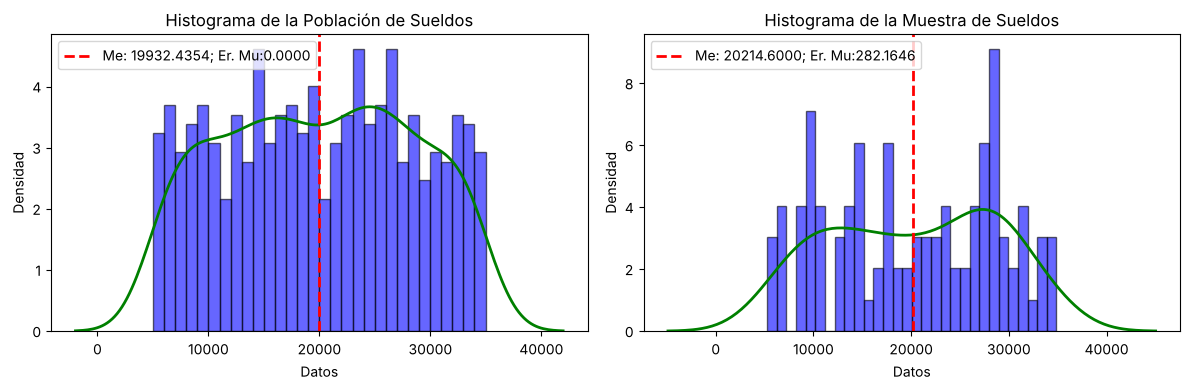

In [9]:
# Llamar a la función f_histograma para la población y la muestra
# Crear una figura con dos subplots uno al lado del otro
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Llamar a la función f_histograma para la población y la muestra
f_histograma(axs[0], sueldos, 0, 'de la Población de Sueldos')
f_histograma(axs[1], muestra, error_muestral, 'de la Muestra de Sueldos')

plt.tight_layout()
plt.show()


## Media muestral de 100 muestras

Se determinan cien (100) muestras de 100 elementos cada una, luego se organizan las medias de todas las muestras en una distribución de probabilidad, el resultado recibe el nombre de distribución muestral de la media (lind2015?).

La variables $x_i$ como parte de la muestra puede ser cualquier trabajador de la población que representa a la población.

Media muestral de la media $\bar{x_i}$

* $\bar{x}_{1}$ significa la media aritmética la primera muestra
* $\bar{x}_{2}$ significa la media aritmética la segunda muestra
* $\bar{x}_{3}$ significa la media aritmética la tercera muestra
* $\bar{x}_{i}$ significa la media aritmética la iésima muestra $ \therefore$
* $\bar{x}_{100}$ significa la media aritmética la muestra $100$

Se manda llamar la función *f_media_muestral(q1, sueldos, n)* y devuelve las medias de cada muestra y la media muestral de todas las medias además del error muestral.

El valor de *q1* es la cantidad de muestras previamente inicialziado.

In [10]:

# Mostrar las medias de las muestras
m_muestras_100, m_muestral_100, error_muestral_100 = f_media_muestral(q1, sueldos, n)

print(m_muestras_100)

print ("Media muestral de ", q1, "muestras",np.round(m_muestral_100, 4) )

print ("Error muestral de la media de ", q1, "muestras",np.round(error_muestral_100, 4) )

[np.float64(18641.87), np.float64(19059.79), np.float64(20920.16), np.float64(20790.01), np.float64(22224.21), np.float64(20419.29), np.float64(18749.54), np.float64(19849.03), np.float64(20151.14), np.float64(20272.86), np.float64(18882.82), np.float64(21166.63), np.float64(18806.08), np.float64(20738.36), np.float64(20654.2), np.float64(20377.21), np.float64(20072.7), np.float64(20747.67), np.float64(19583.2), np.float64(19681.86), np.float64(18537.07), np.float64(19901.0), np.float64(19833.59), np.float64(19346.61), np.float64(19339.65), np.float64(20708.07), np.float64(20038.25), np.float64(18908.57), np.float64(20177.92), np.float64(19467.21), np.float64(20202.04), np.float64(20608.08), np.float64(18700.36), np.float64(19486.44), np.float64(21249.23), np.float64(21564.52), np.float64(20514.38), np.float64(20987.77), np.float64(19781.5), np.float64(20674.91), np.float64(18869.41), np.float64(18759.41), np.float64(19922.09), np.float64(19181.74), np.float64(20362.54), np.float64(200

Con todas las medias muestrales de las 100 muetras se hace el histograma y se compara la media muestral.


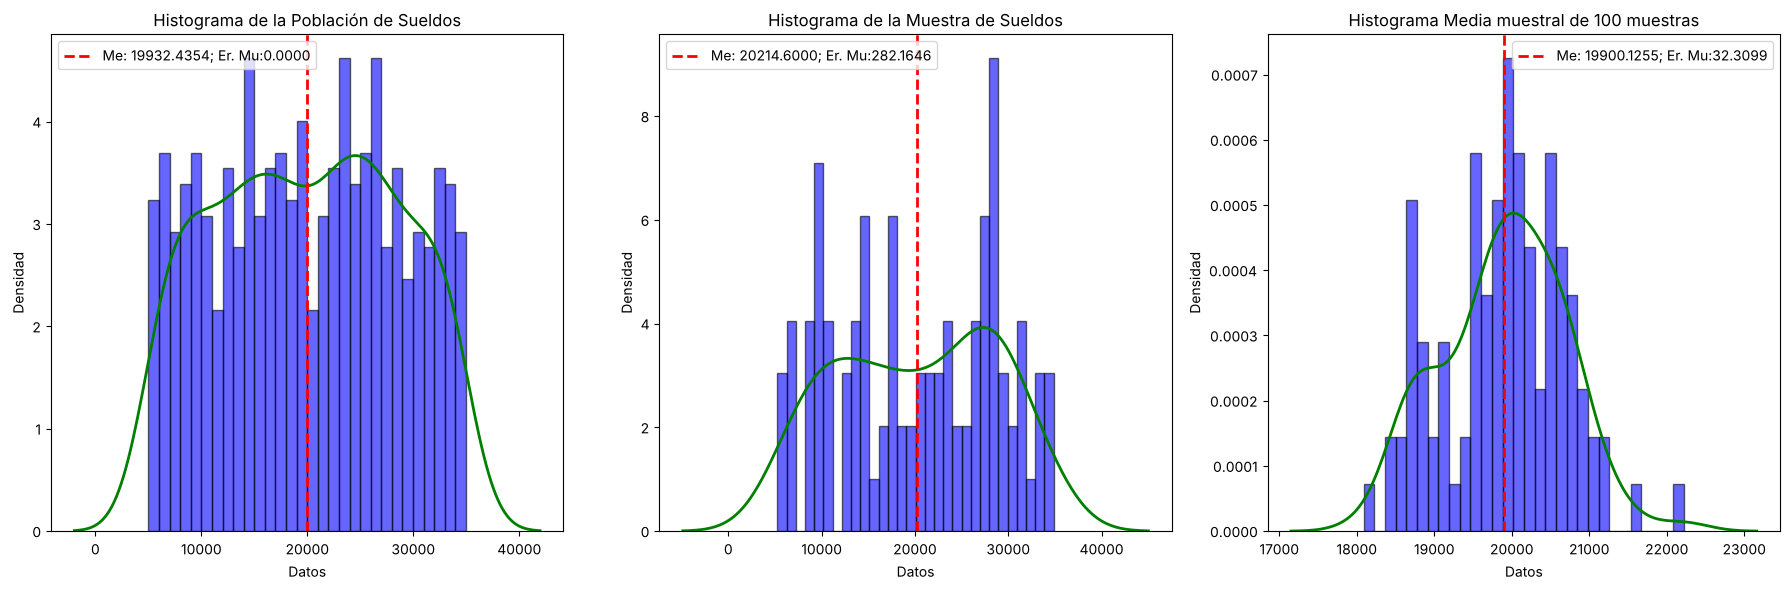

In [11]:
# Llamar a la función f_histograma para la población y la muestra
# Crear una figura con dos subplots uno al lado del otro
# Crear una figura con tres subplots en dos filas
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Llamar a la función f_histograma para la población y la muestra
f_histograma(axs[0], sueldos, 0,'de la Población de Sueldos')
f_histograma(axs[1], muestra, error_muestral, 'de la Muestra de Sueldos')
f_histograma(axs[2], m_muestras_100, error_muestral_100, 'Media muestral de 100 muestras')

plt.tight_layout()
plt.show()

## Media muestral de 1000 muestras

Se determinan mil (1000) muestras de $n=100$ elementos cada una, luego se organizan las medias de todas las muestras en una distribución de probabilidad.

Se manda llamar la función *f_media_muestral(q2, sueldos, n )* y devuelve las medias de cada muestra y la media muestral de todas las medias además del error muestral.

El valor de *q2* es la cantidad de muestras previamente inicializado.



In [12]:
# Mostrar las medias de las muestras
m_muestras_1000, m_muestral_1000, error_muestral_1000 = f_media_muestral(q2, sueldos, n)

print(m_muestras_1000)

print ("Media muestral de ", q2, "muestras",np.round(m_muestral_1000, 4) )

print ("Eror muestral de la media de ", q2, "muestras",np.round(error_muestral_1000, 4) )

[np.float64(20157.25), np.float64(20268.03), np.float64(20380.9), np.float64(19759.75), np.float64(18778.87), np.float64(20383.57), np.float64(18795.92), np.float64(20296.9), np.float64(19886.49), np.float64(19187.16), np.float64(20459.49), np.float64(18580.26), np.float64(19859.94), np.float64(21051.98), np.float64(20663.94), np.float64(20468.44), np.float64(19931.97), np.float64(20733.0), np.float64(19567.19), np.float64(21701.86), np.float64(20485.55), np.float64(20024.11), np.float64(19464.94), np.float64(18968.28), np.float64(21296.31), np.float64(20719.57), np.float64(19933.89), np.float64(21588.42), np.float64(19730.68), np.float64(19862.39), np.float64(19428.89), np.float64(20691.38), np.float64(20336.15), np.float64(19738.72), np.float64(20327.28), np.float64(20177.72), np.float64(19602.19), np.float64(19675.57), np.float64(18893.31), np.float64(20620.58), np.float64(21870.01), np.float64(21248.18), np.float64(20276.85), np.float64(18575.6), np.float64(21011.74), np.float64(21

Al calcular la media muestral de las medias de las $1000$ muestras se comienza a visualizar una curva suavizada mu cercana a la curva de campana.

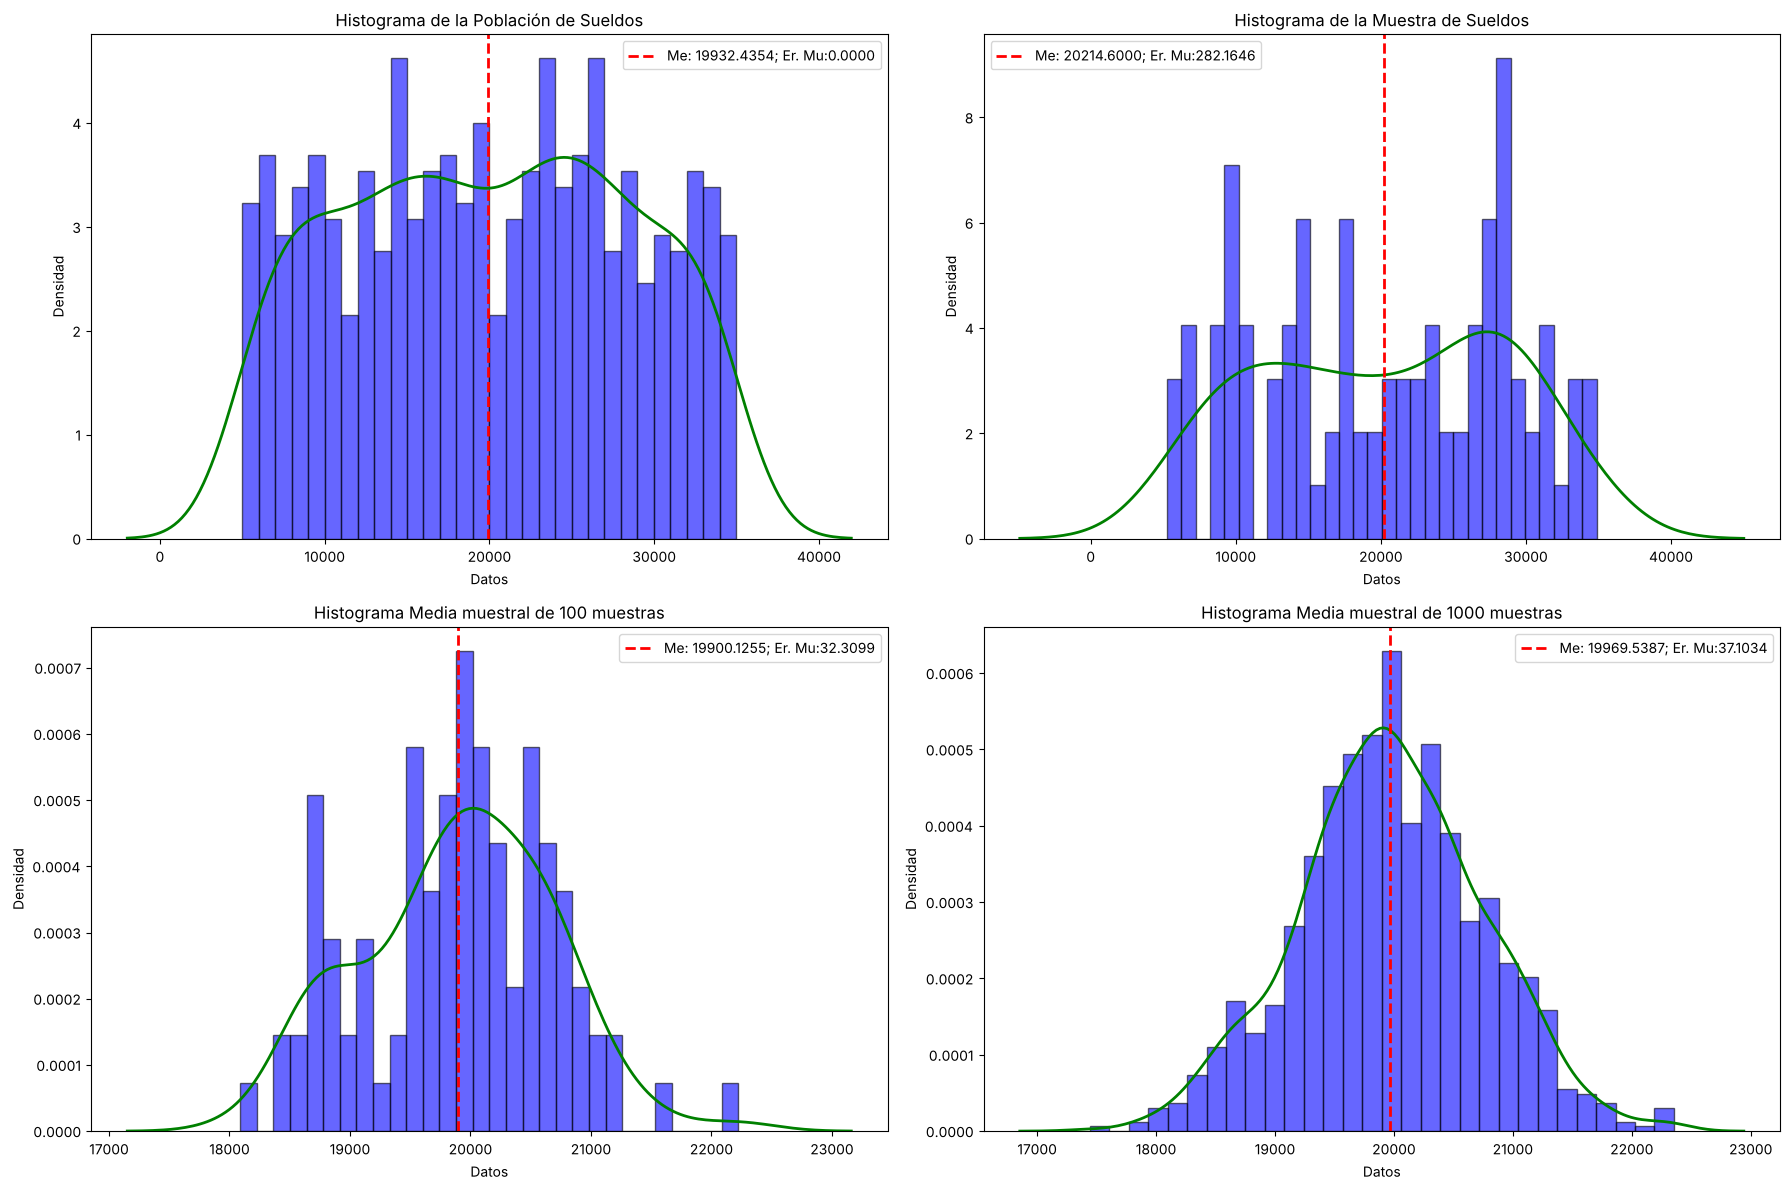

In [13]:
# Llamar a la función f_histograma para la población y la muestra
# Crear una figura con cuatro subplots en dos filas y dos columnas
fig, axs = plt.subplots(2, 2, figsize=(18, 12))

# Llamar a la función f_histograma para la población, la muestra y las medias muestrales
f_histograma(axs[0, 0], sueldos, 0, 'de la Población de Sueldos')
f_histograma(axs[0, 1], muestra, error_muestral, 'de la Muestra de Sueldos')
f_histograma(axs[1, 0], m_muestras_100, error_muestral_100, 'Media muestral de 100 muestras')
f_histograma(axs[1, 1], m_muestras_1000, error_muestral_1000, 'Media muestral de 1000 muestras')

# Mostrar los histogramas
plt.tight_layout()
plt.show()


## Media muestral de 10000 muestras

Se determinan diez mil (10000) muestras de $n=100$ elementos cada una, luego se organizan las medias de todas las muestras en una distribución de probabilidad.

Se manda llamar la función *f_media_muestral(q3, sueldos, n)* y devuelve las medias de cada muestra y la media muestral de todas las medias además del error muestral.

El valor de q3 es la cantidad de meustras previamente inicialziado.



In [14]:
# Mostrar las medias de las muestras
m_muestras_10000, m_muestral_10000, error_muestral_10000 = f_media_muestral(q3, sueldos, n)

print(m_muestras_10000)

print ("Media muestral de ", q3, "muestras",np.round(m_muestral_10000, 4) )

print ("Eror muestral de la media de ", q3, "muestras",np.round(error_muestral_10000, 4) )

[np.float64(18818.81), np.float64(18661.84), np.float64(20254.26), np.float64(21757.05), np.float64(20634.74), np.float64(20383.33), np.float64(21836.55), np.float64(19965.45), np.float64(19896.91), np.float64(20613.66), np.float64(19597.69), np.float64(19498.55), np.float64(20354.72), np.float64(18962.8), np.float64(19568.79), np.float64(19052.17), np.float64(20067.51), np.float64(18533.21), np.float64(20096.86), np.float64(20821.52), np.float64(18487.94), np.float64(20871.04), np.float64(19457.0), np.float64(19843.76), np.float64(19928.52), np.float64(20192.92), np.float64(19383.34), np.float64(20374.76), np.float64(21093.9), np.float64(18380.86), np.float64(19974.79), np.float64(19627.04), np.float64(20835.38), np.float64(20345.68), np.float64(19819.35), np.float64(20416.27), np.float64(20502.8), np.float64(20113.22), np.float64(20176.97), np.float64(19989.56), np.float64(19553.71), np.float64(20479.0), np.float64(19049.36), np.float64(20634.72), np.float64(20166.33), np.float64(201

Al calcular la media muestral de las medias de las $10000$ muestras se dfine mejor una curva suavizada de gauss.

Al tener una curva de campana en la visualizaición de la distribución de las medias se debe interpretar que entre mas muestras se tengan y se calcule la media de todas esas muestras los datos tendra´un comportamiento normal.

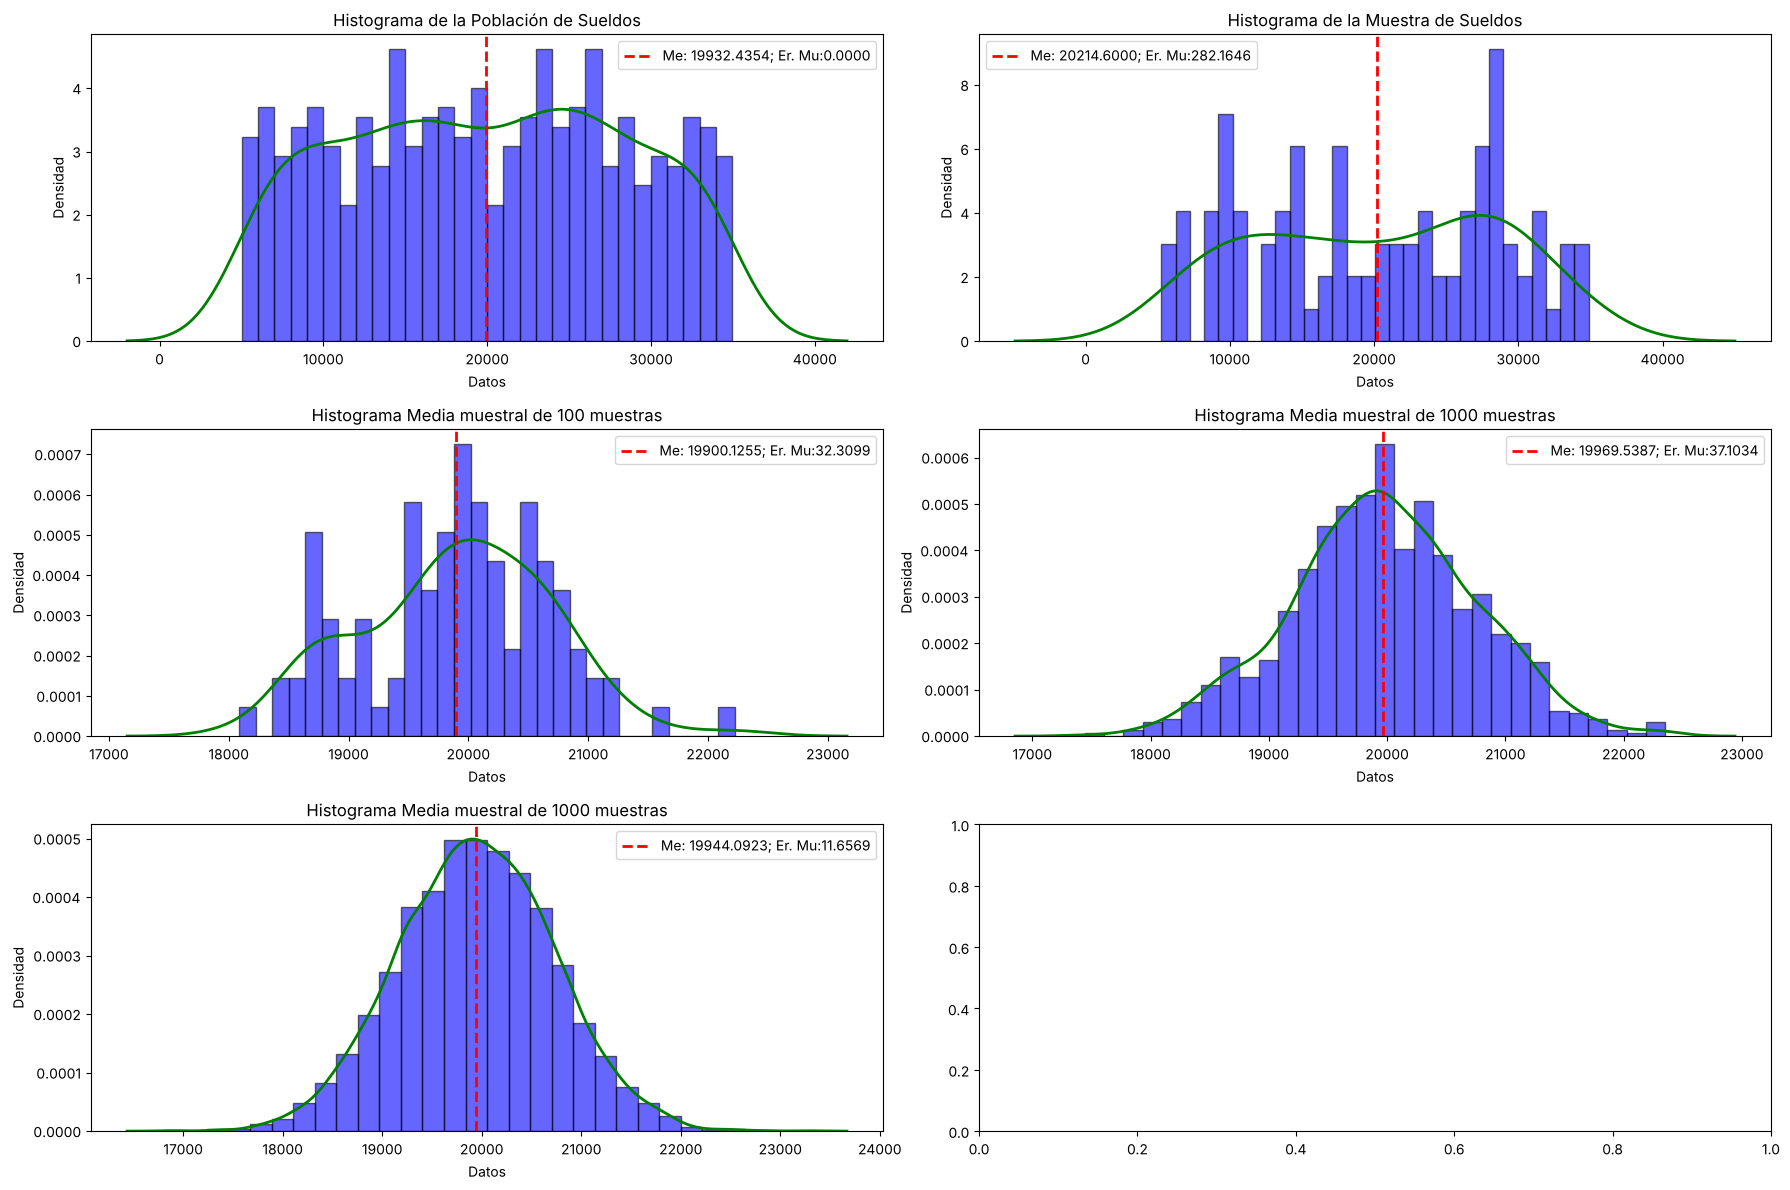

In [15]:
# Llamar a la función f_histograma para la población y la muestra
# Crear una figura con cuatro subplots en dos filas y dos columnas
fig, axs = plt.subplots(3, 2, figsize=(18, 12))

# Llamar a la función f_histograma para la población, la muestra y las medias muestrales
f_histograma(axs[0, 0], sueldos, 0, 'de la Población de Sueldos')
f_histograma(axs[0, 1], muestra, error_muestral, 'de la Muestra de Sueldos')
f_histograma(axs[1, 0], m_muestras_100, error_muestral_100, 'Media muestral de 100 muestras')
f_histograma(axs[1, 1], m_muestras_1000, error_muestral_1000, 'Media muestral de 1000 muestras')
f_histograma(axs[2, 0], m_muestras_10000, error_muestral_10000, 'Media muestral de 1000 muestras')

# Mostrar los histogramas
plt.tight_layout()
plt.show()

¿Qué sucederá con 100000 (cien mil muestras)?

## Media muestral de 100000 muestras

Se determinan diez mil (100000) muestras de $n=100$ elementos cada una, luego se organizan las medias de todas las muestras en una distribución de probabilidad.

Se manda llamar la función *f_media_muestral(q4, sueldos, n)* y devuelve las medias de cada muestra y la media muestral de todas las medias además del error muestral.

El valor de q4 es la cantidad de muestras previamente inicialziado.

In [16]:
# Mostrar las medias de las muestras
m_muestras_100000, m_muestral_100000, error_muestral_100000 = f_media_muestral(q4, sueldos, n)

print(m_muestras_100000)

print ("Media muestral de ", q4, "muestras",np.round(m_muestral_100000, 4) )

print ("Eror muestral de la media de ", q4, "muestras",np.round(error_muestral_100000, 4) )

[np.float64(20340.26), np.float64(19414.56), np.float64(20542.65), np.float64(20065.03), np.float64(19299.15), np.float64(19875.35), np.float64(21100.98), np.float64(19777.4), np.float64(21090.37), np.float64(19766.2), np.float64(19559.6), np.float64(19665.05), np.float64(19103.31), np.float64(18744.67), np.float64(20248.87), np.float64(20179.44), np.float64(19077.71), np.float64(20017.29), np.float64(20023.46), np.float64(20018.23), np.float64(19540.53), np.float64(17891.75), np.float64(19558.3), np.float64(20794.83), np.float64(19534.66), np.float64(18935.51), np.float64(19914.79), np.float64(17777.13), np.float64(19468.92), np.float64(21310.4), np.float64(20566.35), np.float64(18796.76), np.float64(19000.11), np.float64(20679.91), np.float64(20019.7), np.float64(20981.87), np.float64(18860.01), np.float64(19530.48), np.float64(20112.3), np.float64(20420.44), np.float64(20142.98), np.float64(21202.74), np.float64(21463.13), np.float64(19585.56), np.float64(20858.81), np.float64(19614

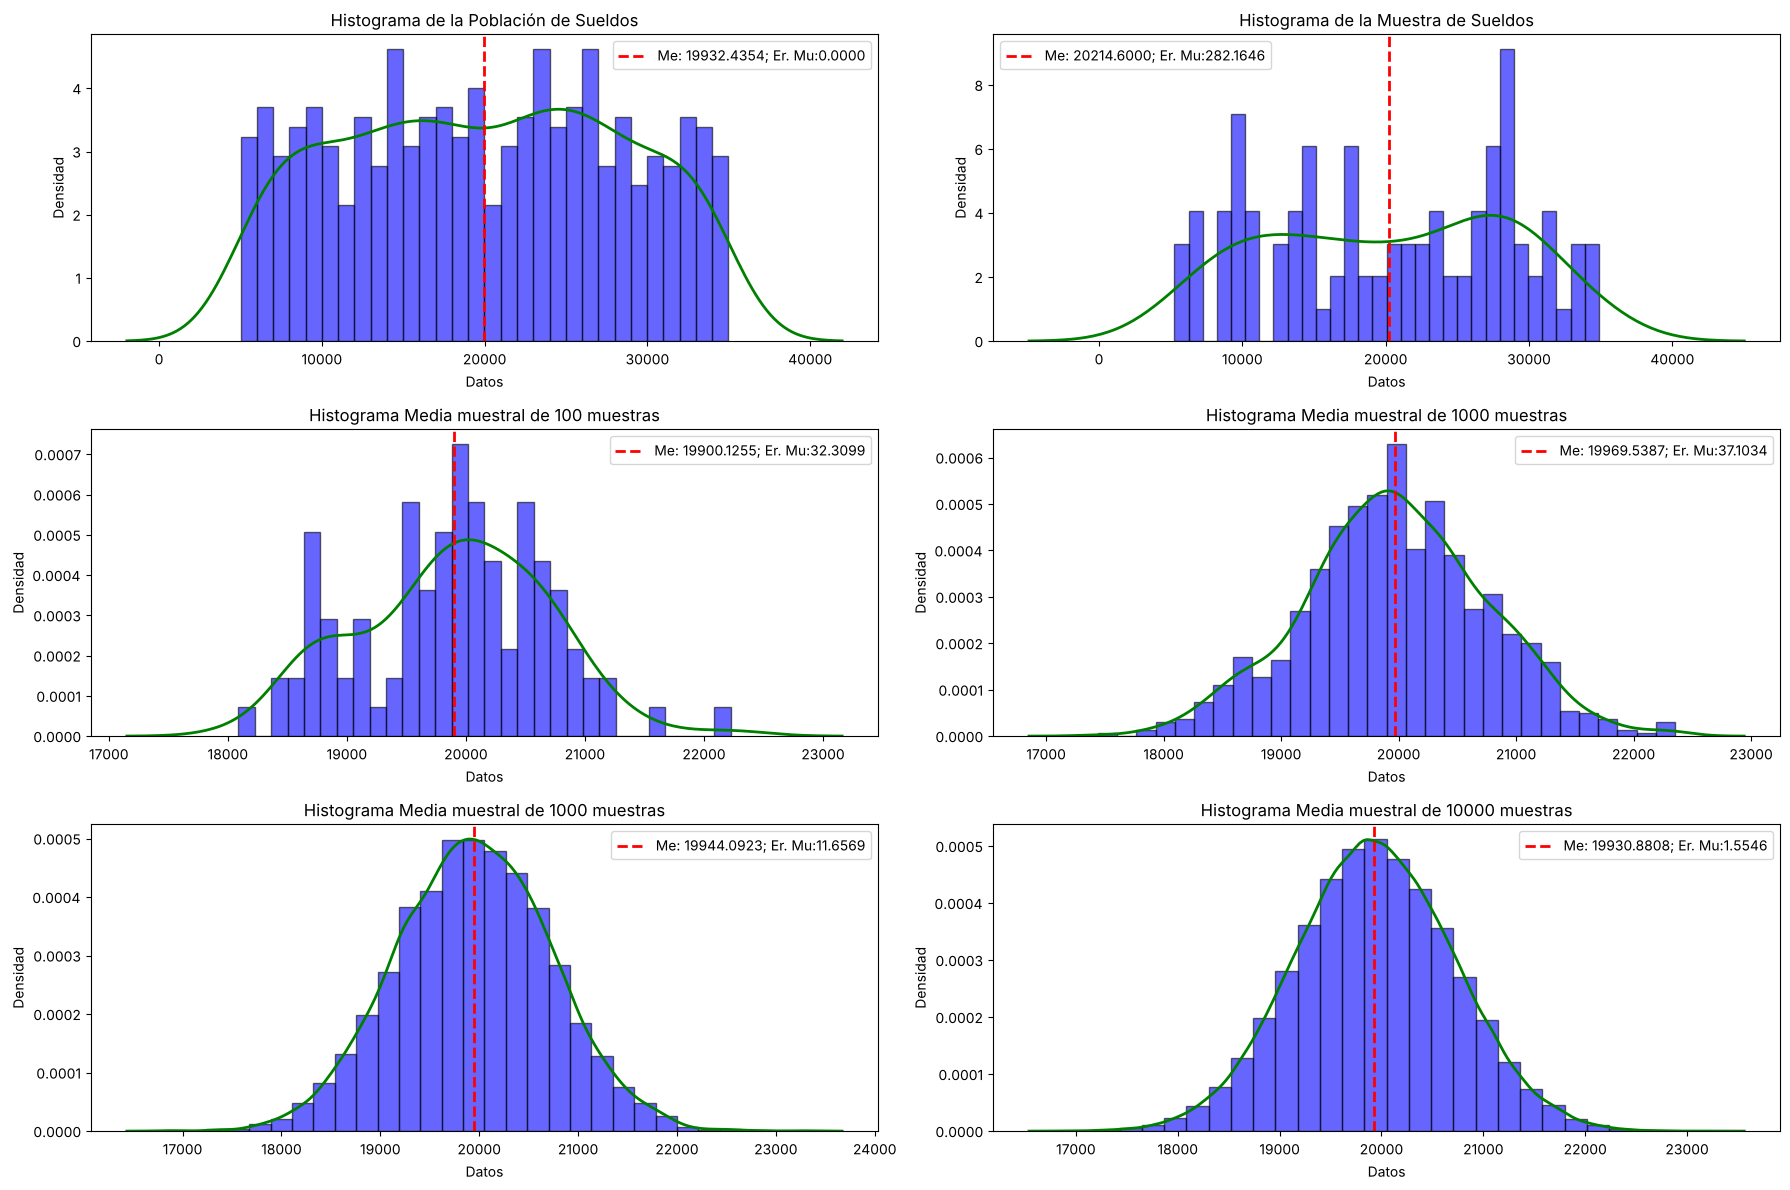

In [17]:
# Llamar a la función f_histograma para la población y la muestra
# Crear una figura con cuatro subplots en dos filas y dos columnas
fig, axs = plt.subplots(3, 2, figsize=(18, 12))

# Llamar a la función f_histograma para la población, la muestra y las medias muestrales
f_histograma(axs[0, 0], sueldos, 0, 'de la Población de Sueldos')
f_histograma(axs[0, 1], muestra, error_muestral, 'de la Muestra de Sueldos')
f_histograma(axs[1, 0], m_muestras_100, error_muestral_100, 'Media muestral de 100 muestras')
f_histograma(axs[1, 1], m_muestras_1000, error_muestral_1000, 'Media muestral de 1000 muestras')
f_histograma(axs[2, 0], m_muestras_10000, error_muestral_10000, 'Media muestral de 1000 muestras')
f_histograma(axs[2, 1], m_muestras_100000, error_muestral_100000, 'Media muestral de 10000 muestras')
# Mostrar los histogramas
plt.tight_layout()
plt.show()

In [18]:
# Comparar la desviación estándar de las medias muestrales con sigma / raíz de n
sigma = np.std(sueldos)  # desviación estándar de la población
print("Desviación estándar de la población (sigma):", np.round(sigma, 4))
print("Error estándar teórico (sigma / raíz de n):", np.round(sigma / np.sqrt(n), 4))
for nombre, medias in [("100", m_muestras_100), ("1000", m_muestras_1000), ("10000", m_muestras_10000), ("100000", m_muestras_100000)]:
    print("Desv. std de las medias de", nombre, "muestras:", np.round(np.std(medias), 4))

Desviación estándar de la población (sigma): 8502.2282
Error estándar teórico (sigma / raíz de n): 850.2228
Desv. std de las medias de 100 muestras: 780.0
Desv. std de las medias de 1000 muestras: 779.1652
Desv. std de las medias de 10000 muestras: 782.0321
Desv. std de las medias de 100000 muestras: 782.4635


# Interpretación

Una distribución muestral de la media es una distribución de las medias de múltiples muestras tomadas de una población.

Es una herramienta fundamental en estadística inferencial, ya que permite hacer inferencias sobre la población a partir de las estadísticas de las muestras.

La importancia de la distribución muestral de la media es para emplearse como herramienta en aspectos tales como:

* En estimación de Parámetros: Permite estimar la media poblacional (𝜇) utilizando la media muestral ($\bar{x}$).

* En intervalos de confianza: Facilita la construcción de intervalos de confianza para la media poblacional.

* En pruebas de hipótesis: Es importante en la realización de pruebas de hipótesis sobre la media poblacional.

Con respecto al comportamiento de las medias muestrales entre mas muestras se tengan la distribucuion de los datos se normaliza y la media muestral de las muestras se acerca a la media poblacional.

Entonces con respecto a la media de la distribución muestral de la media $\mu_{\bar{x}}$ es igual o muy cercana a la media de la población (𝜇).

En relación a la desviación estándar de la distribución muestral de la media ($
\sigma_{\bar{x}}$) es igual a la desviación estándar de la población (𝜎) dividida por la raíz cuadrada del tamaño de la muestra (𝑛).

$$
\sigma_{\bar{x}} = \frac{\sigma}{\sqrt{n}}
$$


Lo visto en este caso da lugar a estas conclusiones: Si la población original no es normal, la distribucion muestral de las medias presenta un comportamiento de normalidad y, entre mas muestras se determinen y sus medias muestrales se calculen, la normalidad es mas definida.  Si la población original tiene una distribución normal, entonces la distribución muestral de la media también será normal, independientemente del tamaño de la muestra.  

Lo anterior da lugar al teorema de límite central, siguiente caso.

## Interpretación de mis resultados

La población de sueldos no es normal: los sueldos se generaron al azar entre 5,000 y 35,000 y su histograma sale parejo y achatado, sin forma de campana. La media poblacional fue $\mu = 19{,}932.4354$.

Con una sola muestra de 100 trabajadores la media fue 20,214.6, o sea un error muestral de 282.1646. Cuando se juntan las medias de muchas muestras, el resultado queda mucho más cerca de la media poblacional:

| Cantidad de muestras | Media de las medias | Error muestral |
|---|---|---|
| 100 | 19,900.1255 | 32.3099 |
| 1,000 | 19,969.5387 | 37.1034 |
| 10,000 | 19,944.0923 | 11.6569 |
| 100,000 | 19,930.8808 | 1.5546 |

El error no baja en cada paso (de 100 a 1,000 muestras subió un poco, de 32.3 a 37.1), porque al final es azar. Pero en general, entre más muestras, más se acerca la media de las medias a la media de la población, y con 100,000 muestras el error es solo de 1.5546.

Los histogramas de las medias se van pareciendo cada vez más a una campana normal, aunque la población original no es normal. Eso es lo que dice el teorema del límite central y es lo que se ve en el caso 30.

Sobre la dispersión, la desviación estándar de las medias muestrales dio alrededor de 782, mientras que $\sigma/\sqrt{n} = 8502.2282/\sqrt{100} = 850.2228$. Sale un poco menor porque las muestras son sin reemplazo de una población chica ($N=650$). Con ese ajuste, $850.22 \times \sqrt{(650-100)/(650-1)} \approx 782.7$, que sí coincide con lo que salió. Lo importante es que la dispersión de las medias es mucho menor que la de la población ($\sigma = 8502.2282$), porque al promediar se compensan los valores muy altos con los muy bajos.

# Bibliografía

* Anderson, David R., Dennis J. Sweeney, and Thomas A. Williams. 2008. Estadística Para Administración y Economía. 10th ed. Australia • Brasil • Corea • España • Estados Unidos • Japón • México • Reino Unido • Singapur: Cengage Learning,.

* Lind, D., Marchal, W., & Wathen, S. (2015). Estadística aplicada a los negocios y la econmía. DécimoSexta edición. ISBN: 978-607-15-1303-8. México, D.F: McGRAW-HILL/INTERAMERICANA EDITORES, S.A. DE C.V.

* Mendenhall, William, Robert J. Beaver, and Barbara M. Beaver. 2006. Introducción a La Probabilidad y Estadística. 13a Edición.

* Walpole, Ronald E., Raymond H. Myers, and Sharon L. Myers. 2012. Probabilidad y Estadística Para Ingeniería y Ciencias. Novena Edición. México: Pearson.

* ChatGPT 4.0 (2024)